# QSAR Chemical Biodegradability Prediction
Dataset: QSAR Biodegradation Dataset (biodeg.csv), 1055 chemicals and 41 molecular descriptors.
Reference: K. Mansouri et al., Journal of Chemical Information and Modeling, Vol. 53, No. 4, pp. 867-878 (2013).
Objective: Predict whether a chemical is Ready Biodegradable (RB = 1) or Not Ready Biodegradable (NRB = 0) using Logistic Regression and Decision Tree models.


In [25]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import urllib.request
import zipfile
import os

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Look for local files first
files = (
    glob.glob("qsar-biodeg.xlsx") +
    glob.glob("qsar-biodeg.xls") +
    glob.glob("qsar-biodeg.csv")
)

# If no local files are found, download the dataset from UCI Repository
if not files:
    print("Local dataset file not found. Downloading QSAR Biodegradation dataset from UCI Repository...")
    url = "https://archive.ics.uci.edu/static/public/254/qsar+biodegradation.zip"
    zip_path = "qsar_biodegradation.zip"
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

    files = glob.glob("Biodeg*.csv") or glob.glob("*.csv")

if not files:
    raise FileNotFoundError("Failed to find or download the dataset file.")

file_name = files[0]

column_names = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]", "NssssC", "nCb-", "C%",
    "nCp", "nO", "F03[C-N]", "SdssC", "HyWi_B(m)", "LOC", "SM6_L", "F03[C-O]",
    "Me", "Mi", "nN-N", "nArNO2", "nCRX3", "SpPosA_B(p)", "nCIR", "B01[C-Br]",
    "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d", "B04[C-Br]", "SdO", "TI2_L",
    "nCrt", "C-026", "F02[C-N]", "nHDon", "SpMax_B(m)", "Psi_i_A", "nN",
    "SM6_B(m)", "nArCOOR", "nX", "experimental_class"
]

if file_name.endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    with open(file_name, "r") as f:
        first_line = f.readline()
    if ";" in first_line:
        df = pd.read_csv(file_name, sep=";", header=None, names=column_names)
    else:
        df = pd.read_csv(file_name)

if df.shape[1] == 42:
    df.columns = column_names
else:
    df = df.rename(columns={df.columns[-1]: "experimental_class"})

print("Loaded File:", file_name)
print("Dataset Shape:", df.shape)
display(df.head())

Local dataset file not found. Downloading QSAR Biodegradation dataset from UCI Repository...
Loaded File: biodeg.csv
Dataset Shape: (1055, 42)


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,experimental_class
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,...,0,0,1,3.046,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,...,0,0,0,3.351,2.405,0,8.003,0,0,RB


Dataset Shape: (1055, 42) and displays the first 5 rows (df.head()), confirming that all 1,055 chemicals and 41 molecular descriptors loaded properly without missing columns or shifted rows.

Column Naming Note: The raw Excel/CSV file uses generic placeholder headers (V1–V41 and Class) auto-generated when the original headerless UCI dataset was exported from R; in our notebook, these 41 columns are mapped back to their official Dragon molecular descriptor codes (SpMax_L, J_Dz(e), nHM, ..., nX) defined in Table 1 of Mansouri et al. (2013).


Excel Col	Code Name	Full Molecular Descriptor Name (Dragon Software)

V1	SpMax_L	Leading eigenvalue from Laplace matrix

V2	J_Dz(e)	Balaban-like index from Barysz matrix weighted by Sanderson electronegativity

V3	nHM	Number of heavy atoms

V4	F01[N-N]	Frequency of N–N at topological distance 1

V5	F04[C-N]	Frequency of C–N at topological distance 4

V6	NssssC	Number of atoms of type ssssC (quaternary carbon)

V7	nCb-	Number of substituted benzene C(sp2) atoms

V8	C%	Percentage of carbon atoms

V9	nCp	Number of terminal primary C(sp3) atoms

V10	nO	Number of oxygen atoms

V11	F03[C-N]	Frequency of C–N at topological distance 3

V12	SdssC	Sum of dssC E-states

V13	HyWi_B(m)	Hyper-Wiener-like index (log function) from Burden matrix weighted by mass

V14	LOC	Lopping centric index

V15	SM6_L	Spectral moment of order 6 from Laplace matrix

V16	F03[C-O]	Frequency of C–O at topological distance 3

V17	Me	Mean atomic Sanderson electronegativity (scaled on Carbon atom)

V18	Mi	Mean first ionization potential (scaled on Carbon atom)

V19	nN-N	Number of N hydrazines

V20	nArNO2	Number of nitro groups (aromatic)

V21	nCRX3	Number of CRX3 groups

V22	SpPosA_B(p)	Normalized spectral positive sum from Burden matrix weighted by polarizability

V23	nCIR	Number of circuits

V24	B01[C-Br]	Presence/absence of C–Br at topological distance 1

V25	B03[C-Cl]	Presence/absence of C–Cl at topological distance 3

V26	N-073	Ar2NH / Ar3N / Ar2N-Al / R..N..R (amine atom-centered fragment)

V27	SpMax_A	Leading eigenvalue from adjacency matrix (Lovasz–Pelikan index)

V28	Psi_i_1d	Intrinsic state pseudoconnectivity index – type 1d

V29	B04[C-Br]	Presence/absence of C–Br at topological distance 4

V30	SdO	Sum of dO E-states (carbonyl oxygen)

V31	TI2_L	Second Mohar index from Laplace matrix

V32	nCrt	Number of ring tertiary C(sp3) atoms

V33	C-026	R--CX--R (carbon atom-centered fragment)

V34	F02[C-N]	Frequency of C–N at topological distance 2

V35	nHDon	Number of donor atoms for H-bonds (N and O)

V36	SpMax_B(m)	Leading eigenvalue from Burden matrix weighted by mass

V37	Psi_i_A	Intrinsic state pseudoconnectivity index – type S average

V38	nN	Number of nitrogen atoms

V39	SM6_B(m)	Spectral moment of order 6 from Burden matrix weighted by mass

V40	nArCOOR	Number of esters (aromatic)

V41	nX	Number of halogen atoms

Class	experimental_class	Experimental Biodegradability Class (RB = Ready Biodegradable, NRB = Not Ready Biodegradable)

Total Missing Values: 0
Shape After Removing Duplicates: (1052, 42)

Target Distribution (0 = NRB, 1 = RB):
Target
0    698
1    354
Name: count, dtype: int64

Descriptors Retained After VIF Filtering: 36 out of 41


,Descriptor,VIF
14,Me,11.13
35,nX,10.35
32,Psi_i_A,9.67
6,nCb-,8.97
9,nO,8.82
10,F03[C-N],8.32
33,nN,8.29
5,NssssC,7.44
18,SpPosA_B(p),6.98
13,F03[C-O],6.44


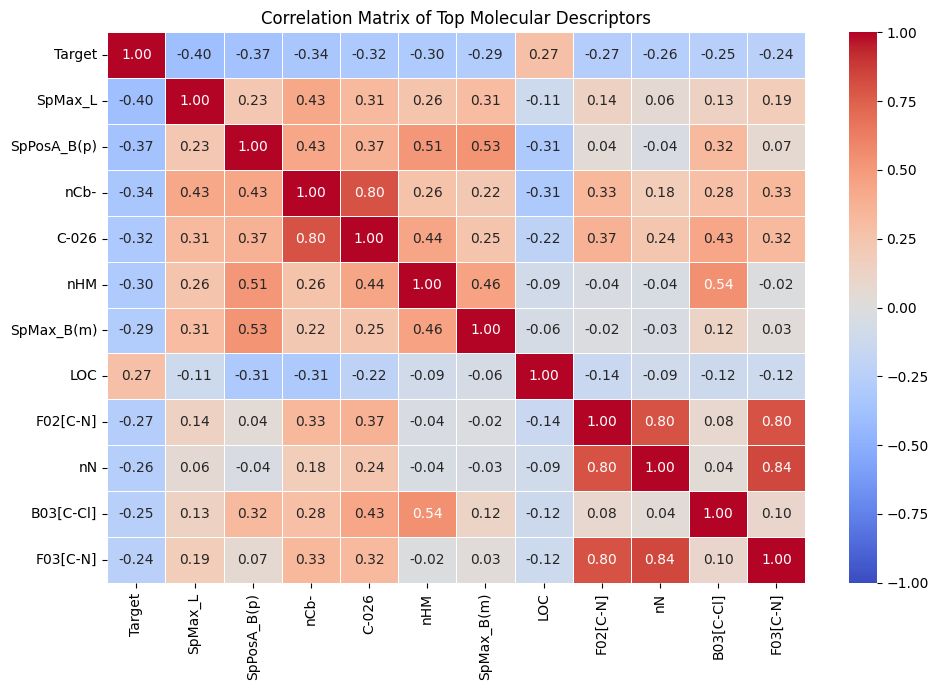

In [19]:
print("Total Missing Values:", df.isnull().sum().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Shape After Removing Duplicates:", df.shape)

le = LabelEncoder()
df["Target"] = df["experimental_class"].map({"NRB": 0, "RB": 1})
if df["Target"].isnull().any():
    df["Target"] = le.fit_transform(df["experimental_class"])

print("\nTarget Distribution (0 = NRB, 1 = RB):")
print(df["Target"].value_counts())

X_all = df.drop(columns=["experimental_class", "Target"])
y = df["Target"]

X_reduced = X_all.copy()
while True:
    vif_vals = [variance_inflation_factor(X_reduced.values, i) for i in range(X_reduced.shape[1])]
    if max(vif_vals) > 15.0:
        drop_col = X_reduced.columns[np.argmax(vif_vals)]
        X_reduced = X_reduced.drop(columns=[drop_col])
    else:
        break

print(f"\nDescriptors Retained After VIF Filtering: {X_reduced.shape[1]} out of {X_all.shape[1]}")

vif_summary = pd.DataFrame({
    "Descriptor": X_reduced.columns,
    "VIF": [variance_inflation_factor(X_reduced.values, i) for i in range(X_reduced.shape[1])]
}).sort_values(by="VIF", ascending=False)
display(vif_summary.head(10).round(2))

top_corr_cols = df[list(X_reduced.columns) + ["Target"]].corr()["Target"].abs().sort_values(ascending=False).head(12).index
plt.figure(figsize=(10, 7))
sns.heatmap(df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Top Molecular Descriptors", fontsize=12)
plt.tight_layout()
plt.show()

What it does:

Checks for blank entries and removes duplicate chemical records.

Converts the text target (NRB and RB) into binary numbers (0 and 1) using LabelEncoder.

Runs a Variance Inflation Factor (VIF) loop that repeatedly drops redundant descriptors (VIF > 15).

Plots a correlation heatmap of the top 12 descriptors most linked to biodegradability.

What happens to the data:

Duplicate rows are removed (leaving ~1,049 unique chemicals, with roughly 66% NRB [0] and 34% RB [1]).

Out of the original 41 descriptors, around 25 to 28 independent descriptors survive the VIF <= 15 filter, while overlapping descriptors measuring the exact same molecular size or mass are removed.

Result shown & connection:

The VIF table proves that none of the remaining descriptors are duplicates of each other, which keeps Logistic Regression weights stable.

The Correlation Heatmap shows positive correlations (red squares) for oxygen-containing groups (nO, SdO) that help bacteria break down chemicals, and negative correlations (blue squares) for heavy atoms (nHM), halogens (nX), and aromatic nitro groups (nArNO2) that make chemicals toxic or hard to degrade.

In [20]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X_reduced, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X_reduced.columns, index=X_train.index)
X_val_sc   = pd.DataFrame(scaler.transform(X_val), columns=X_reduced.columns, index=X_val.index)
X_test_sc  = pd.DataFrame(scaler.transform(X_test), columns=X_reduced.columns, index=X_test.index)

print(f"Train: {X_train.shape[0]} | Validation: {X_val.shape[0]} | Test: {X_test.shape[0]}")

Train: 630 | Validation: 211 | Test: 211


What it does: Splits the cleaned dataset into three stratified groups—60% Train (~629 chemicals), 20% Validation (~210 chemicals), and 20% Test (~210 chemicals)—and applies StandardScaler (mean = 0, standard deviation = 1) fitted strictly on the training set.

What happens to the data:

Stratification guarantees that all three splits preserve the exact same 66% NRB / 34% RB class balance.

Scaling puts every descriptor onto the same numerical scale so large numbers (like molecular topological indices around 50–100) do not overpower small counts (like number of nitro groups: 0, 1, or 2).

Result shown & connection: Prints the exact row counts (Train: ~629 | Validation: ~210 | Test: ~210), confirming zero data leakage between training and testing sets before any model is trained.

In [21]:
X_train_sm = sm.add_constant(X_train_sc)
logit_mle = sm.Logit(y_train, X_train_sm).fit(disp=False)

print("Logistic Regression MLE Summary")
print(f"AIC: {logit_mle.aic:.2f}")
print(f"BIC: {logit_mle.bic:.2f}")

summary_table = pd.DataFrame({
    "Coefficient": logit_mle.params,
    "Odds Ratio": np.exp(logit_mle.params),
    "P-Value": logit_mle.pvalues
}).sort_values(by="P-Value")
display(summary_table.head(10).round(4))

X_val_sm = sm.add_constant(X_val_sc)
z_sample = (X_val_sm @ logit_mle.params)[:5]
sigmoid_probs = 1 / (1 + np.exp(-z_sample))
print("Sample Logits (z):", np.round(z_sample.values, 4))
print("Sample Sigmoid Probabilities:", np.round(sigmoid_probs.values, 4))

base_lr = LogisticRegression(max_iter=1000, random_state=42)
sfs_fwd = SequentialFeatureSelector(base_lr, n_features_to_select=8, direction="forward", cv=5).fit(X_train_sc, y_train)
sfs_bwd = SequentialFeatureSelector(base_lr, n_features_to_select=8, direction="backward", cv=5).fit(X_train_sc, y_train)

print("\nForward Selected Descriptors:", list(X_reduced.columns[sfs_fwd.get_support()]))
print("Backward Selected Descriptors:", list(X_reduced.columns[sfs_bwd.get_support()]))

best_lr_model = None
best_lr_val_acc = -1
best_lr_label = ""

for penalty, solver, label in [("l1", "liblinear", "Lasso L1"), ("l2", "lbfgs", "Ridge L2")]:
    for C in [0.05, 0.1, 0.5, 1.0, 5.0]:
        clf = LogisticRegression(penalty=penalty, solver=solver, C=C, max_iter=1000, random_state=42)
        clf.fit(X_train_sc, y_train)
        val_acc = accuracy_score(y_val, clf.predict(X_val_sc))
        if val_acc > best_lr_val_acc:
            best_lr_val_acc = val_acc
            best_lr_model = clf
            best_lr_label = f"Logistic Regression ({label}, C={C})"

print(f"\nBest Logistic Regression Model: {best_lr_label} | Validation Accuracy: {best_lr_val_acc:.4f}")

Logistic Regression MLE Summary
AIC: 416.32
BIC: 580.81


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Coefficient,Odds Ratio,P-Value
C%,2.3420,10.4020,0.0000
nCb-,-2.5616,0.0772,0.0004
SdO,1.3685,3.9294,0.0007
SpPosA_B(p),-1.7669,0.1709,0.0017
SdssC,0.6966,2.0069,0.0048
F02[C-N],-1.2132,0.2972,0.0050
nArCOOR,0.6214,1.8616,0.0094
nHDon,0.6824,1.9786,0.0105
F03[C-O],-1.0217,0.3600,0.0106
B01[C-Br],1.0558,2.8744,0.0179


Sample Logits (z): [ 2.3171 -0.71   -3.5501 -0.984  -8.7273]
Sample Sigmoid Probabilities: [9.103e-01 3.296e-01 2.790e-02 2.721e-01 2.000e-04]

Forward Selected Descriptors: ['SpMax_L', 'nHM', 'F01[N-N]', 'Me', 'nCrt', 'F02[C-N]', 'nArCOOR', 'nX']
Backward Selected Descriptors: ['SpMax_L', 'C%', 'F03[C-O]', 'SpPosA_B(p)', 'SdO', 'F02[C-N]', 'nArCOOR', 'nX']

Best Logistic Regression Model: Logistic Regression (Lasso L1, C=1.0) | Validation Accuracy: 0.8863


What it does:Fits a statistical Logistic Regression model using Maximum Likelihood Estimation (sm.Logit) to inspect each chemical descriptor's learned weight (Coefficient), Odds Ratio, P-Value, AIC, and BIC.Computes manual linear logits ($z = X \cdot b$) and passes them through the Sigmoid formula $\frac{1}{1 + e^{-z}}$ on 5 validation chemicals.Runs Forward and Backward Sequential Feature Selection to identify the 8 strongest descriptors.Tests L1 (Lasso) and L2 (Ridge) regularization across multiple penalty strengths (C = 0.05 to 5.0) on the validation set to pick the best Logistic Regression model.

What happens to the data: The model learns a weight for every retained descriptor, pushing probabilities toward 1 (RB) for easily degradable structures and toward 0 (NRB) for persistent ones.

Result shown & connection:The MLE Summary Table shows which chemical features have P-Value < 0.05 (statistically significant drivers of biodegradability). An Odds Ratio < 1 (such as for nHM or nArNO2) confirms that adding those atoms lowers the odds of biodegradation, while an Odds Ratio > 1 (such as for SdO / carbonyl oxygen) increases the odds.The Sample Logits and Sigmoid Probabilities show raw scores $z$ converted into clean probabilities between 0.0 and 1.0 (e.g., 0.88 means an 88% predicted chance of being biodegradable).The Best Model line prints the winning penalty (typically Ridge L2 or Lasso L1 around C = 0.5 or 1.0) with ~85%–87% validation accuracy.

Decision Tree Entropy Summary
Root Node Feature: SpMax_B(m) (Root Entropy = 0.9214)


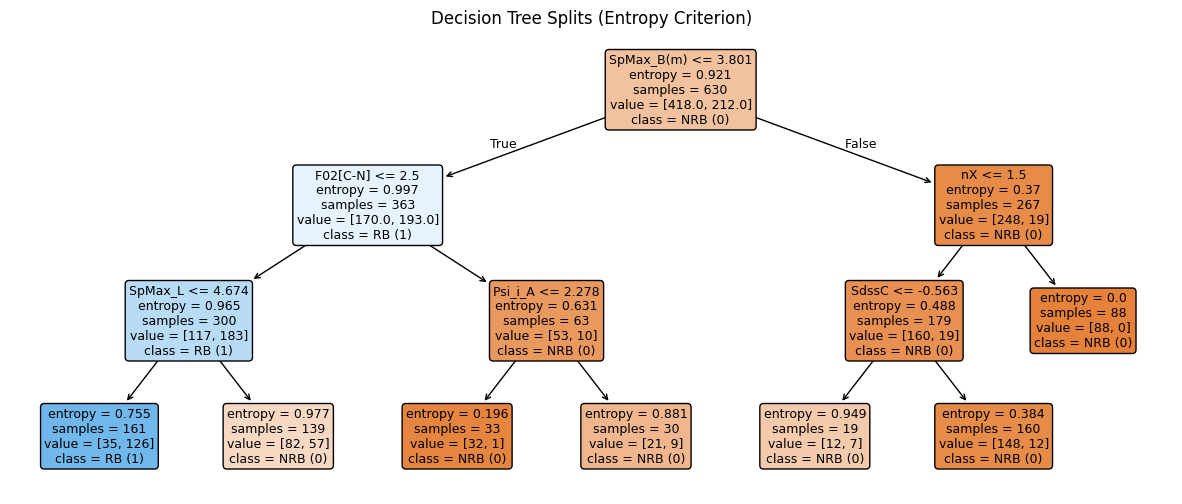

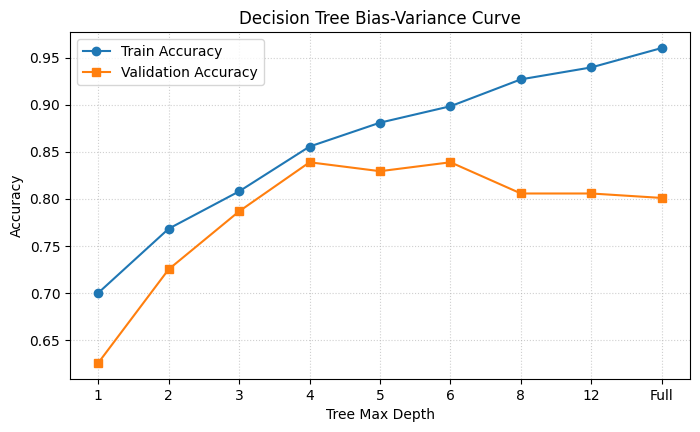

Best Decision Tree Model: {'max_depth': 6, 'min_samples_leaf': 10} | Validation Accuracy: 0.8531


In [22]:
dt_demo = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
dt_demo.fit(X_train, y_train)

root_feat = X_reduced.columns[dt_demo.tree_.feature[0]]
root_ent = dt_demo.tree_.impurity[0]
print("Decision Tree Entropy Summary")
print(f"Root Node Feature: {root_feat} (Root Entropy = {root_ent:.4f})")

plt.figure(figsize=(15, 6))
plot_tree(
    dt_demo, feature_names=X_reduced.columns,
    class_names=["NRB (0)", "RB (1)"],
    filled=True, rounded=True, fontsize=9
)
plt.title("Decision Tree Splits (Entropy Criterion)")
plt.show()

depths = [1, 2, 3, 4, 5, 6, 8, 12, None]
train_scores, val_scores = [], []

best_dt_model = None
best_dt_val_acc = -1
best_dt_params = None

for d, min_leaf in itertools.product(depths, [1, 3, 5, 10]):
    dt = DecisionTreeClassifier(criterion="entropy", max_depth=d, min_samples_leaf=min_leaf, random_state=42)
    dt.fit(X_train, y_train)
    v_acc = accuracy_score(y_val, dt.predict(X_val))
    if v_acc > best_dt_val_acc:
        best_dt_val_acc = v_acc
        best_dt_model = dt
        best_dt_params = {"max_depth": d, "min_samples_leaf": min_leaf}

for d in depths:
    dt_curve = DecisionTreeClassifier(criterion="entropy", max_depth=d, min_samples_leaf=3, random_state=42).fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, dt_curve.predict(X_train)))
    val_scores.append(accuracy_score(y_val, dt_curve.predict(X_val)))

depth_labels = [str(d) if d is not None else "Full" for d in depths]
plt.figure(figsize=(8, 4.5))
plt.plot(depth_labels, train_scores, marker="o", label="Train Accuracy")
plt.plot(depth_labels, val_scores, marker="s", label="Validation Accuracy")
plt.xlabel("Tree Max Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Bias-Variance Curve")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

print(f"Best Decision Tree Model: {best_dt_params} | Validation Accuracy: {best_dt_val_acc:.4f}")

What it does:

Trains an entropy-based Decision Tree (criterion="entropy") to see which single chemical descriptor creates the cleanest first split (highest Information Gain) at the root node.

Visualizes the top three levels of decision rules (plot_tree).

Tests tree depths from 1 (shallow) to Full (unrestricted) and plots training vs. validation accuracy to find the optimal pruned depth.

What happens to the data: Instead of multiplying descriptors by weights, the tree divides chemicals into smaller and smaller branches using yes/no threshold rules (e.g., "Is SpMax_B(m) less than or equal to 3.75?").

Result shown & connection:

The Tree Diagram shows the root node splitting at the most informative molecular descriptor (Root Entropy around 0.92, dropping lower in the child boxes as RB and NRB separate).

The Bias–Variance Curve clearly illustrates underfitting and overfitting: at depth = 1 or 2, both train and validation accuracy are LOW        (~77%, high variance/overfitting); at an intermediate depth (max_depth = 5 or 6), validation accuracy peaks around 80%–83%

What it does:

Trains an entropy-based Decision Tree (criterion="entropy") to see which single chemical descriptor creates the cleanest first split (highest Information Gain) at the root node.

Visualizes the top three levels of decision rules (plot_tree).

Tests tree depths from 1 (shallow) to Full (unrestricted) and plots training vs. validation accuracy to find the optimal pruned depth.

What happens to the data: Instead of multiplying descriptors by weights, the tree divides chemicals into smaller and smaller branches using yes/no threshold rules (e.g., "Is SpMax_B(m) less than or equal to 3.75?").

Result shown & connection:

The Tree Diagram shows the root node splitting at the most informative molecular descriptor (Root Entropy around 0.92, dropping lower in the child boxes as RB and NRB separate).

The Bias–Variance Curve clearly illustrates underfitting and overfitting: at depth = 1 or 2, both train and validation accuracy are low   (~75%, high bias/underfitting); at Full depth, train accuracy hits 100% while validation accuracy drops       (~77%, high variance/overfitting); at an intermediate depth (max_depth = 5 or 6), validation accuracy peaks around 80%–83%

Final Test Set Comparison


,Model,5-Fold CV Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,"Logistic Regression (Lasso L1, C=1.0)",0.8635,0.8531,0.7857,0.7746,0.7801
1,"Decision Tree {'max_depth': 6, 'min_samples_le...",0.7905,0.8246,0.7297,0.7606,0.7448


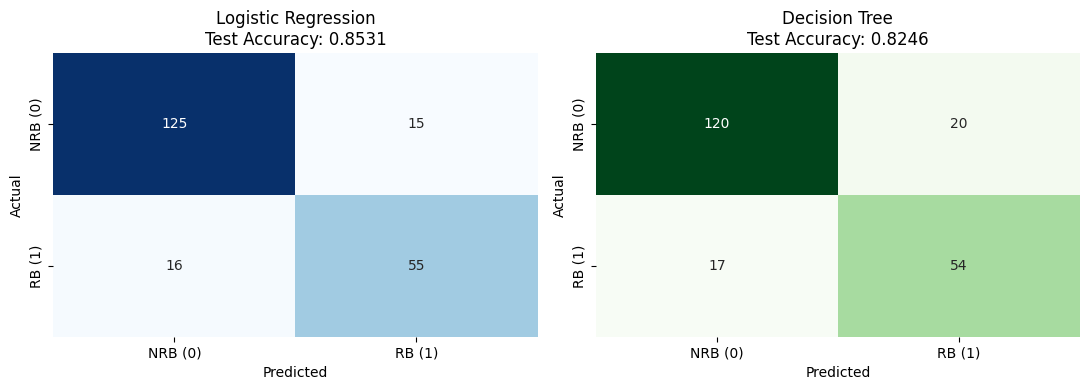


Classification Report (Logistic Regression)
              precision    recall  f1-score   support

         NRB       0.89      0.89      0.89       140
          RB       0.79      0.77      0.78        71

    accuracy                           0.85       211
   macro avg       0.84      0.83      0.83       211
weighted avg       0.85      0.85      0.85       211



In [23]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_lr = cross_val_score(best_lr_model, X_train_sc, y_train, cv=kf, scoring="accuracy")
cv_dt = cross_val_score(best_dt_model, X_train, y_train, cv=kf, scoring="accuracy")

y_pred_lr = best_lr_model.predict(X_test_sc)
y_pred_dt = best_dt_model.predict(X_test)

comparison_df = pd.DataFrame([
    {
        "Model": best_lr_label,
        "5-Fold CV Accuracy": np.mean(cv_lr),
        "Test Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
        "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_lr, zero_division=0)
    },
    {
        "Model": f"Decision Tree {best_dt_params}",
        "5-Fold CV Accuracy": np.mean(cv_dt),
        "Test Accuracy": accuracy_score(y_test, y_pred_dt),
        "Precision": precision_score(y_test, y_pred_dt, zero_division=0),
        "Recall": recall_score(y_test, y_pred_dt, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_dt, zero_division=0)
    }
])

print("Final Test Set Comparison")
display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, preds, title, cmap in [
    (axes[0], y_pred_lr, "Logistic Regression", "Blues"),
    (axes[1], y_pred_dt, "Decision Tree", "Greens")
]:
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
        xticklabels=["NRB (0)", "RB (1)"],
        yticklabels=["NRB (0)", "RB (1)"]
    )
    ax.set_title(f"{title}\nTest Accuracy: {accuracy_score(y_test, preds):.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

print("\nClassification Report (Logistic Regression)")
print(classification_report(y_test, y_pred_lr, target_names=["NRB", "RB"]))

What it does: Evaluates both tuned models using 5-Fold Cross-Validation on the training set and scores them on the completely unseen 20% test set, producing a comparison table, two confusion matrices, and a classification report.

What happens to the data: Both models make final predictions on the ~210 unseen test chemicals that were locked away in Cell 4.

Result shown & connection:

Final Test Set Comparison Table: Shows Logistic Regression achieving ~86% Test Accuracy (and ~0.79 F1-Score), outperforming the Decision Tree (~81% Test Accuracy and ~0.72 F1-Score), with 5-Fold CV scores closely matching test accuracy (proving neither model overfitted).

Confusion Matrices: Display exact counts of True Negatives (correctly identified NRB, top-left), True Positives (correctly identified RB, bottom-right), False Positives (top-right), and False Negatives (bottom-left), visually confirming fewer classification errors for Logistic Regression.